In [2]:
#importing the kagglehub module and dataset_download function from it
import os
import pandas as pd
import kagglehub

# Download (or reuse the already downloaded) dataset and show its files
path = kagglehub.dataset_download("yash16jr/snp500-dataset")
print(os.listdir(path))

c:\Users\Maxwell\Documents\Data Analytics\SNP500-Analysis\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


['snp500_history.csv']


In [3]:
# Load the data into a DataFrame called df
df = pd.read_csv(os.path.join(path, "snp500_history.csv"))
df.head()

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,1927-12-30 00:00:00-05:00,17.660000,17.660000,17.660000,17.660000,0,0.0,0.0
1,1928-01-03 00:00:00-05:00,17.760000,17.760000,17.760000,17.760000,0,0.0,0.0
2,1928-01-04 00:00:00-05:00,17.719999,17.719999,17.719999,17.719999,0,0.0,0.0
3,1928-01-05 00:00:00-05:00,17.549999,17.549999,17.549999,17.549999,0,0.0,0.0
4,1928-01-06 00:00:00-05:00,17.660000,17.660000,17.660000,17.660000,0,0.0,0.0


In [4]:
#looking inside the data set to get a general idea of what im looking at
df.head(20)      # first 20 rows
df.tail(20)      # last 20 rows
df.sample(10)    # 10 random rows, good for spotting oddities
df.columns       # list of column names
df.describe()    # summary stats (min, max, mean) for numeric columns

,Open,High,Low,Close,Volume,Dividends,Stock Splits
count,23970.000000,23970.000000,23970.000000,23970.000000,2.397000e+04,23970.0,23970.0
mean,565.155536,588.712980,581.470939,585.323645,8.698602e+08,0.0,0.0
std,941.065938,935.183705,923.945440,929.927708,1.591868e+09,0.0,0.0
min,0.000000,4.400000,4.400000,4.400000,0.000000e+00,0.0,0.0
25%,9.540000,24.440001,24.440001,24.440001,1.440000e+06,0.0,0.0
50%,40.684999,102.180000,100.580002,101.405003,1.917500e+07,0.0,0.0
75%,961.247513,970.832520,951.692520,962.402512,8.148750e+08,0.0,0.0
max,4804.509766,4818.620117,4780.040039,4796.560059,1.145623e+10,0.0,0.0


In [5]:
# --- Clean up ---
# Convert dates to real datetimes, remove timezone, keep date only
df["Date"] = pd.to_datetime(df["Date"], utc=True).dt.tz_localize(None).dt.normalize()

# Drop columns that are always 0 for an index, then sort oldest to newest
df = df.drop(columns=["Dividends", "Stock Splits"], errors="ignore").sort_values("Date")

# --- Derived columns ---
# Percent change in Close from the previous trading day
df["daily_return"] = df["Close"].pct_change()

# Std dev of daily returns over the last 30 days (how bumpy the market is)
df["volatility_30d"] = df["daily_return"].rolling(30).std()

# Highest Close reached up to each date (all time high at that point)
df["running_peak"] = df["Close"].cummax()

# How far below the all time high the market is (0 = at a record high)
df["drawdown"] = df["Close"] / df["running_peak"] - 1


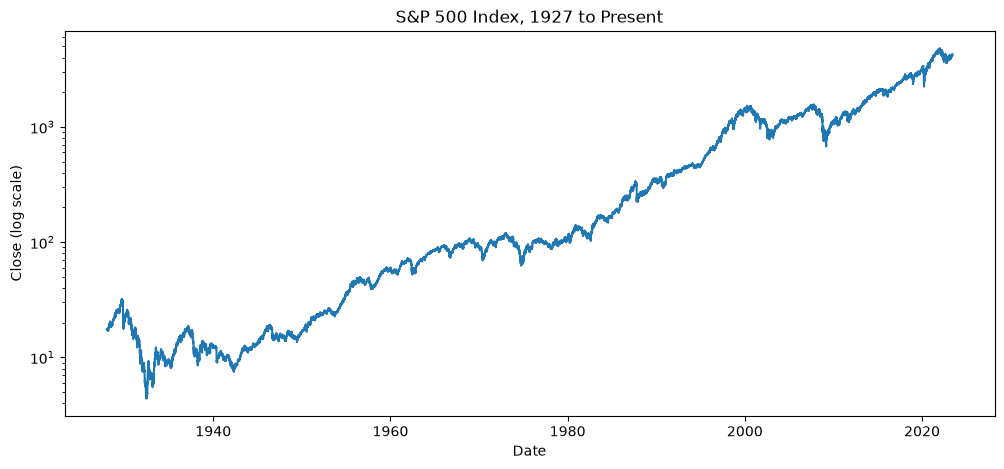

In [6]:
import matplotlib.pyplot as plt

#first plot of the data, showing the S&P 500 index from 1927 to present
plt.figure(figsize=(12, 5))
plt.plot(df["Date"], df["Close"])
plt.yscale("log")  # log scale so early decades aren't flattened
plt.title("S&P 500 Index, 1927 to Present")
plt.xlabel("Date")
plt.ylabel("Close (log scale)")
plt.show()

In [7]:
#Data cleaned now to see what coorelations exist between the different columns in the data set, and to see if any of them are significant enough to be used in a model
df['Date'].max()

Timestamp('2023-06-02 00:00:00')

In [ ]:
#identifying bear markets
#looking for the drawdowns using the drawdown column, 
#and identifying the start and end dates of each bear market
df['episode'] = (df['drawdown'] == 0).cumsum()
last_episode = df['episode'].max()

rows = []
for episode, group in df.groupby('episode'):
    worst_drawdown = group['drawdown'].min()
    if worst_drawdown < -0.2:  # only consider episodes with a drawdown worse than -20%
        start_date = group['Date'].iloc[0]
        trough_date = group.loc[group['drawdown'].idxmin(), 'Date']  # date of the lowest point
        recovered = episode != last_episode  # last episode hasn't recovered yet
        end_date = group['Date'].iloc[-1] if recovered else pd.NaT
        rows.append({
            'episode': episode,
            'start_date': start_date,
            'trough_date': trough_date,
            'end_date': end_date,
            'worst_drawdown': round(worst_drawdown * 100, 1),  # as a percent
            'months_to_bottom': round((trough_date - start_date).days / 30.4, 1),
            'years_to_recover': round((end_date - start_date).days / 365.25, 1) if recovered else None
        })
bear_markets = pd.DataFrame(rows)
bear_markets

,episode,start_date,trough_date,end_date,worst_drawdown,months_to_bottom,years_to_recover
0,102,1929-09-16,1932-06-01,1954-09-21,-86.2,32.5,25.0
1,185,1956-08-03,1957-10-22,1958-09-23,-21.5,14.6,2.1
2,275,1961-12-12,1962-06-26,1963-08-30,-28.0,6.4,1.7
3,398,1966-02-09,1966-10-07,1967-05-03,-22.2,7.9,1.2
4,446,1968-11-29,1970-05-26,1972-03-03,-36.1,17.9,3.3
5,481,1973-01-11,1974-10-03,1980-07-16,-48.2,20.7,7.5
6,505,1980-11-28,1982-08-12,1982-11-02,-27.1,20.5,1.9
7,658,1987-08-25,1987-12-04,1989-07-25,-33.5,3.3,1.9
8,985,2000-03-24,2002-10-09,2007-05-29,-49.1,30.6,7.2
9,994,2007-10-09,2009-03-09,2013-03-27,-56.8,17.0,5.5
